# Module 4: full adders and a 4-bit Qiskit extension

**Abert Kabore**  
PhD student in Advanced and Equitable Computing

The original 1-bit and 2-bit gate sequences below are retained from the supplied
class notebook. Their sampling calls use `SamplerV2` instead of the deprecated
`Sampler`. The **4-bit assignment solution** begins after those examples.

If the active Python kernel needs dependencies, run this once in a separate cell:

```python
%pip install qiskit==2.5.2 qiskit-aer==0.17.2 matplotlib==3.9.2
```

The next cell reports the versions actually used; installation logs from the
supplied notebook are not evidence of the current environment.

In [1]:
import platform
from importlib.metadata import version

print(f"Python {platform.python_version()}")
for package in ("qiskit", "qiskit-aer", "matplotlib", "numpy"):
    print(f"{package} {version(package)}")

Python 3.11.0
qiskit 2.5.2
qiskit-aer 0.17.2
matplotlib 3.9.2
numpy 2.3.2


In [2]:
from qiskit import QuantumCircuit
from qiskit_aer.primitives import SamplerV2
from qiskit.visualization import plot_histogram

In [3]:
# Define functions for the ripple carry adder.
def sum(circ, cin, a, b):
    circ.cx(a,b)
    circ.cx(cin,b)

def carry(circ, cin, a, b, cout):
    circ.ccx(a, b, cout)
    circ.cx(a, b)
    circ.ccx(cin, b, cout)

def carry_rev(circ, cin, a, b, cout):
    circ.ccx(cin, b, cout)
    circ.cx(a, b)
    circ.ccx(a, b, cout)


In [4]:
#quantum sum of 3 bits (1-bit FA)
qc = QuantumCircuit(4,2)

# encode inputs in qubits 0, 1 and 2
#use the X gates to toggle the input qubit values
xinput = [1,1,0]  #vary these input values for all 8 cases
if xinput[2] == 1:
  qc.x(0)
if xinput[1] == 1:
  qc.x(1)
if xinput[0] == 1:
  qc.x(2)
qc.barrier()

#QC carry ...
carry(qc, 0, 1, 2, 3)
qc.barrier()

qc.cx(1,2)
qc.barrier()

#QC sum ...
sum(qc, 0, 1, 2)
qc.barrier()

# extract outputs
qc.measure(2,0) # extract Sum value
qc.measure(3,1) # extract Cout value

qc.draw()

░                 ░       ░            ░       
q_0: ──────░─────────────■───░───────░────────■───░───────
     ┌───┐ ░             │   ░       ░        │   ░       
q_1: ┤ X ├─░───■────■────┼───░───■───░───■────┼───░───────
     ├───┤ ░   │  ┌─┴─┐  │   ░ ┌─┴─┐ ░ ┌─┴─┐┌─┴─┐ ░ ┌─┐   
q_2: ┤ X ├─░───■──┤ X ├──■───░─┤ X ├─░─┤ X ├┤ X ├─░─┤M├───
     └───┘ ░ ┌─┴─┐└───┘┌─┴─┐ ░ └───┘ ░ └───┘└───┘ ░ └╥┘┌─┐
q_3: ──────░─┤ X ├─────┤ X ├─░───────░────────────░──╫─┤M├
           ░ └───┘     └───┘ ░       ░            ░  ║ └╥┘
c: 2/════════════════════════════════════════════════╩══╩═
                                                     0  1

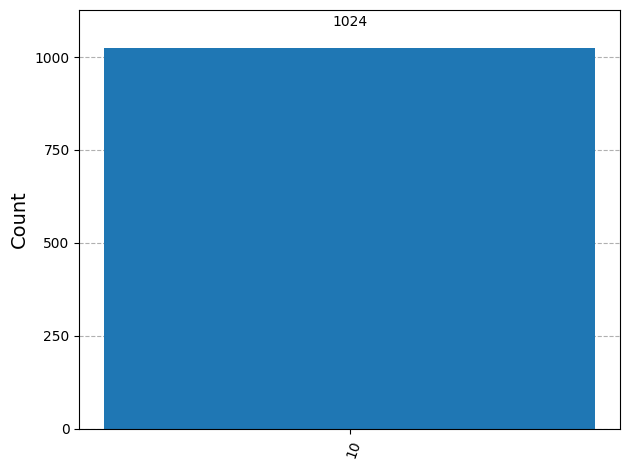

In [5]:
results = SamplerV2(seed=4).run([qc], shots=1024).result()
statistics = results[0].data.c.get_counts()
plot_histogram(statistics)

### Observations

- All 1,024 shots produced 10, confirming the 1-bit addition 1 + 1 + 0 = 2.
- The label is carry-out followed by sum: carry-out 1 and sum 0. The vertical axis shows shot counts from the ideal Aer simulator.


In [6]:
#quantum sum of 3 bits (1-bit FA)
#Another way with 5-bits
#(anticipating a design for an n-bit FA)
qc = QuantumCircuit(5,2)

# encode inputs in qubits 0, 1 and 2
#use the X gates to toggle the input qubit values
xinput = [1,1,1]  #vary these input values for all 8 cases
if xinput[2] == 1:
  qc.x(0)
if xinput[1] == 1:
  qc.x(1)
if xinput[0] == 1:
  qc.x(2)
qc.barrier()

#QC carry ...
carry(qc, 0, 1, 2, 3)
qc.barrier()

qc.cx(3,4)
qc.barrier()

#QC carry reverse ...
carry_rev(qc, 0, 1, 2, 3)
qc.barrier()

#QC sum ...
sum(qc, 0, 1, 2)
qc.barrier()

# extract outputs
qc.measure(2,0) # extract Sum value
qc.measure(4,1) # extract Cout value

qc.draw()


┌───┐ ░                 ░       ░                 ░            ░       
q_0: ┤ X ├─░─────────────■───░───────░───■─────────────░────────■───░───────
     ├───┤ ░             │   ░       ░   │             ░        │   ░       
q_1: ┤ X ├─░───■────■────┼───░───────░───┼────■────■───░───■────┼───░───────
     ├───┤ ░   │  ┌─┴─┐  │   ░       ░   │  ┌─┴─┐  │   ░ ┌─┴─┐┌─┴─┐ ░ ┌─┐   
q_2: ┤ X ├─░───■──┤ X ├──■───░───────░───■──┤ X ├──■───░─┤ X ├┤ X ├─░─┤M├───
     └───┘ ░ ┌─┴─┐└───┘┌─┴─┐ ░       ░ ┌─┴─┐└───┘┌─┴─┐ ░ └───┘└───┘ ░ └╥┘   
q_3: ──────░─┤ X ├─────┤ X ├─░───■───░─┤ X ├─────┤ X ├─░────────────░──╫────
           ░ └───┘     └───┘ ░ ┌─┴─┐ ░ └───┘     └───┘ ░            ░  ║ ┌─┐
q_4: ──────░─────────────────░─┤ X ├─░─────────────────░────────────░──╫─┤M├
           ░                 ░ └───┘ ░                 ░            ░  ║ └╥┘
c: 2/══════════════════════════════════════════════════════════════════╩══╩═
                                                                       0  1

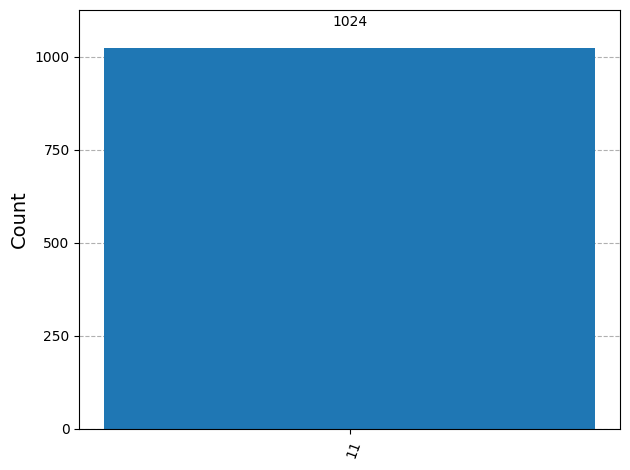

In [7]:
results = SamplerV2(seed=4).run([qc], shots=1024).result()
statistics = results[0].data.c.get_counts()
plot_histogram(statistics)

### Observations

- All 1,024 shots produced 11, confirming the 1-bit addition 1 + 1 + 1 = 3.
- Both measured bits are 1: carry-out 1 and sum 1. This five-qubit version copies the carry-out before applying reverse-CARRY.


In [8]:
#2-bit FA
qc = QuantumCircuit(7,3)

#Qubits:  0    1    2   3              4   5     6
#Input:  cin0  a0  b0  cin1(=cout0)   a1   b1   cin2(=cout1)

#Qubits:    0    1    2            3     4    5             6
#Output:   cin0  a0  a0+b0+cin0   |0>   a1   a1+b1+cin1   cin2(=cout1)

#use the X gates to toggle the input qubit values
a = [1,1]
b = [1,0]
if a[1] == 1:
  qc.x(1)
if a[0] == 1:
  qc.x(4)

if b[1] == 1:
  qc.x(2)
if b[0] == 1:
  qc.x(5)

qc.barrier()

#QC carry ...
carry(qc, 0, 1, 2, 3)
qc.barrier()

carry(qc, 3,4,5,6)
qc.barrier()

qc.cx(4,5)
qc.barrier()
sum(qc, 3,4,5)
qc.barrier()
qc.barrier()
qc.barrier()

#QC carry reverse ...
carry_rev(qc, 0, 1, 2, 3)
qc.barrier()

#QC sum ...
sum(qc, 0, 1, 2)
qc.barrier()

# extract outputs
qc.measure(2,0) # extract Sum_0
qc.measure(5,1) # extract Sum_1
qc.measure(6,2) # extract Sum_2

qc.draw()

░                 ░                 ░       ░            ░  ░  ░ »
q_0: ──────░─────────────■───░─────────────────░───────░────────────░──░──░─»
     ┌───┐ ░             │   ░                 ░       ░            ░  ░  ░ »
q_1: ┤ X ├─░───■────■────┼───░─────────────────░───────░────────────░──░──░─»
     └───┘ ░   │  ┌─┴─┐  │   ░                 ░       ░            ░  ░  ░ »
q_2: ──────░───■──┤ X ├──■───░─────────────────░───────░────────────░──░──░─»
           ░ ┌─┴─┐└───┘┌─┴─┐ ░                 ░       ░            ░  ░  ░ »
q_3: ──────░─┤ X ├─────┤ X ├─░─────────────■───░───────░────────■───░──░──░─»
     ┌───┐ ░ └───┘     └───┘ ░             │   ░       ░        │   ░  ░  ░ »
q_4: ┤ X ├─░─────────────────░───■────■────┼───░───■───░───■────┼───░──░──░─»
     ├───┤ ░                 ░   │  ┌─┴─┐  │   ░ ┌─┴─┐ ░ ┌─┴─┐┌─┴─┐ ░  ░  ░ »
q_5: ┤ X ├─░─────────────────░───■──┤ X ├──■───░─┤ X ├─░─┤ X ├┤ X ├─░──░──░─»
     └───┘ ░                 ░ ┌─┴─┐└───┘┌─┴─┐ ░ └───┘ ░ └───┘└───┘ ░  ░  ░ »
q_6: ──────░─────────────────░─┤ X ├─────┤ X ├─░───────░────────────░──░──░─»
           ░                 ░ └───┘     └───┘ ░       ░            ░  ░  ░ »
c: 3/═══════════════════════════════════════════════════════════════════════»
                                                                            »
«                     ░            ░          
«q_0: ──■─────────────░────────■───░──────────
«       │             ░        │   ░          
«q_1: ──┼────■────■───░───■────┼───░──────────
«       │  ┌─┴─┐  │   ░ ┌─┴─┐┌─┴─┐ ░ ┌─┐      
«q_2: ──■──┤ X ├──■───░─┤ X ├┤ X ├─░─┤M├──────
«     ┌─┴─┐└───┘┌─┴─┐ ░ └───┘└───┘ ░ └╥┘      
«q_3: ┤ X ├─────┤ X ├─░────────────░──╫───────
«     └───┘     └───┘ ░            ░  ║       
«q_4: ────────────────░────────────░──╫───────
«                     ░            ░  ║ ┌─┐   
«q_5: ────────────────░────────────░──╫─┤M├───
«                     ░            ░  ║ └╥┘┌─┐
«q_6: ────────────────░────────────░──╫──╫─┤M├
«                     ░            ░  ║  ║ └╥┘
«c: 3/════════════════════════════════╩══╩══╩═
«                                     0  1  2

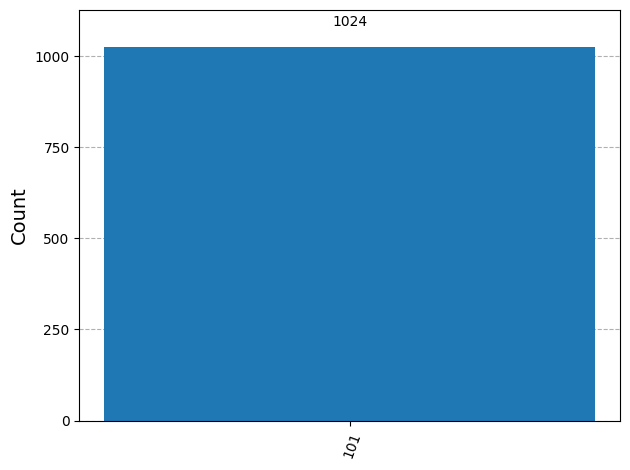

In [9]:
results = SamplerV2(seed=4).run([qc], shots=1024).result()
statistics = results[0].data.c.get_counts()
plot_histogram(statistics)

### Observations

- All 1,024 shots produced 101, confirming the 2-bit addition 11 + 10 = 101 (3 + 2 = 5).
- The leftmost output bit is the carry-out; the lower two sum bits are 01. This is an ideal simulator result with relative frequency 1 at 101.


# 4-bit Ripple-Carry Adder

The 1-bit and 2-bit examples above follow the Vedral–Barenco–Ekert (1995 preprint; journal publication in 1996) construction. The same pattern generalizes to $n$ bits:

1. **Carry ripple (up):** for $i = 0 \dots n-1$, `carry(c_i, a_i, b_i, c_{i+1})` computes carry $c_{i+1}$.
2. **Top bit:** `cx(a_{n-1}, b_{n-1})` undoes the XOR left by `carry`, then `sum(c_{n-1}, a_{n-1}, b_{n-1})` writes $s_{n-1}$ into $b_{n-1}$.
3. **Uncompute (down):** for $i = n-2 \dots 0$, `carry_rev` restores $c_{i+1}$ to $|0\rangle$, then `sum` writes $s_i$ into $b_i$.

**Qubit layout** (same as the 2-bit example, $3n+1$ qubits; 13 for $n=4$):

| bit $i$ | $c_i$ (carry in) | $a_i$ | $b_i$ → $s_i$ |
|---|---|---|---|
| 0 | q0 | q1 | q2 |
| 1 | q3 | q4 | q5 |
| 2 | q6 | q7 | q8 |
| 3 | q9 | q10 | q11 |
| carry out $c_4$ = $s_4$ | q12 | | |

After the circuit runs, $b_i$ holds sum bit $s_i$ and q12 holds the carry-out. The $a$ register and $c_0$ come back unchanged, and the internal carries $c_1 \dots c_3$ return to $|0\rangle$.
Sum bit $s_i$ is measured into classical bit $i$, so the measured bitstring **is** the binary value of $a+b+c_{in}$ (5 bits, 0–31).

**Result provenance.** All counts and histograms in this notebook come from
executing the displayed Qiskit circuits on the local, ideal Qiskit Aer simulator
with 1,024 shots per measured circuit, no noise model, and random seed 4.
`Statevector` independently checks the unmeasured circuits. Expected values use
ordinary integer addition only as a reference; simulator counts are obtained
from `get_counts()`. No quantum hardware experiment is claimed. Each count histogram has one bar at 1,024 counts for these basis-state inputs
on the ideal simulator (relative frequency 1).

**Sources:** the supplied class notebook;
[Vedral, Barenco, and Ekert, Quantum Networks for Elementary Arithmetic Operations](https://arxiv.org/abs/quant-ph/9511018);
[IBM Qiskit bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering);
and [Qiskit Aer SamplerV2](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.primitives.SamplerV2.html).


In [10]:
from qiskit import QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer.primitives import SamplerV2
import matplotlib.pyplot as plt


def adder_qubits(i):
    """Return (c_i, a_i, b_i), using the original 2-bit qubit layout."""
    return 3 * i, 3 * i + 1, 3 * i + 2


def ripple_carry_adder(n, a, b, cin=0, measure=True):
    """Build an n-bit ripple-carry adder computing a + b + cin.

    a, b: integers in [0, 2**n); bit i is loaded into a_i / b_i.
    cin  : initial carry-in (0 or 1), loaded into qubit c_0
    """
    if not (0 <= a < 2**n and 0 <= b < 2**n):
        raise ValueError(f"a and b must be in [0, {2**n - 1}] for a {n}-bit adder")
    if cin not in (0, 1):
        raise ValueError("cin must be 0 or 1")

    qr = QuantumRegister(3 * n + 1, "q")
    qc = QuantumCircuit(qr, name=f"{n}-bit adder")
    cout = 3 * n

    # encode inputs with X gates
    if cin:
        qc.x(0)
    for i in range(n):
        _, ai, bi = adder_qubits(i)
        if (a >> i) & 1:
            qc.x(ai)
        if (b >> i) & 1:
            qc.x(bi)
    qc.barrier()

    # QC carry ... (ripple up)
    for i in range(n):
        ci, ai, bi = adder_qubits(i)
        # c_{i+1} is qubit ci + 3; the last is cout.
        carry(qc, ci, ai, bi, ci + 3)
    qc.barrier()

    # most significant bit: undo the a XOR b from carry, then sum
    ci, ai, bi = adder_qubits(n - 1)
    qc.cx(ai, bi)
    sum(qc, ci, ai, bi)
    qc.barrier()

    # QC carry reverse + sum ... (ripple down)
    for i in range(n - 2, -1, -1):
        ci, ai, bi = adder_qubits(i)
        carry_rev(qc, ci, ai, bi, ci + 3)
        sum(qc, ci, ai, bi)
        qc.barrier()

    if measure:
        cr = ClassicalRegister(n + 1, "s")
        qc.add_register(cr)
        for i in range(n):
            qc.measure(adder_qubits(i)[2], cr[i])   # extract Sum_i
        qc.measure(cout, cr[n])                     # extract Cout (Sum_n)
    return qc


def run_counts(circuits, shots=1024):
    """Run circuits on the Aer sampler and return a list of counts dicts."""
    result = SamplerV2(seed=4).run(circuits, shots=shots).result()
    return [r.data.s.get_counts() for r in result]

### Example: 11 + 6 = 17

$a = 1011_2$, $b = 0110_2$, so the expected output is $10001_2 = 17$ (carry-out set).

In [11]:
# 4-bit full adder: load binary 1011 and 0110.
a, b = 11, 6
qc = ripple_carry_adder(4, a, b)
print(f"qubits: {qc.num_qubits}, depth: {qc.depth()}")
print(f"gates: {dict(qc.count_ops())}")
qc.draw(fold=120)

qubits: 13, depth: 26
gates: {'cx': 16, 'ccx': 14, 'barrier': 6, 'x': 5, 'measure': 5}


░                                ░                 ░                           ░                          »
 q_0: ──────░─────────────■──────────────────░─────────────────░───────────────────────────░──────────────────────────»
      ┌───┐ ░             │                  ░                 ░                           ░                          »
 q_1: ┤ X ├─░───■────■────┼──────────────────░─────────────────░───────────────────────────░──────────────────────────»
      └───┘ ░   │  ┌─┴─┐  │                  ░                 ░                           ░                          »
 q_2: ──────░───■──┤ X ├──■──────────────────░─────────────────░───────────────────────────░──────────────────────────»
            ░ ┌─┴─┐└───┘┌─┴─┐                ░                 ░                           ░                          »
 q_3: ──────░─┤ X ├─────┤ X ├──■─────────────░─────────────────░───────────────────────────░───■───────────────────■──»
      ┌───┐ ░ └───┘     └───┘  │             ░                 ░                           ░   │                   │  »
 q_4: ┤ X ├─░───■────■─────────┼─────────────░─────────────────░───────────────────────────░───┼────■────■────■────┼──»
      ├───┤ ░   │  ┌─┴─┐       │             ░                 ░                           ░   │  ┌─┴─┐  │  ┌─┴─┐┌─┴─┐»
 q_5: ┤ X ├─░───■──┤ X ├───────■─────────────░─────────────────░───────────────────────────░───■──┤ X ├──■──┤ X ├┤ X ├»
      └───┘ ░ ┌─┴─┐└───┘     ┌─┴─┐           ░                 ░                           ░ ┌─┴─┐└───┘┌─┴─┐└───┘└───┘»
 q_6: ──────░─┤ X ├──────────┤ X ├──■────────░─────────────────░───■───────────────────■───░─┤ X ├─────┤ X ├──────────»
            ░ └───┘          └───┘  │        ░                 ░   │                   │   ░ └───┘     └───┘          »
 q_7: ──────░───■────■──────────────┼────────░─────────────────░───┼────■────■────■────┼───░──────────────────────────»
      ┌───┐ ░   │  ┌─┴─┐            │        ░                 ░   │  ┌─┴─┐  │  ┌─┴─┐┌─┴─┐ ░                          »
 q_8: ┤ X ├─░───■──┤ X ├────────────■────────░─────────────────░───■──┤ X ├──■──┤ X ├┤ X ├─░──────────────────────────»
      └───┘ ░ ┌─┴─┐└───┘          ┌─┴─┐      ░                 ░ ┌─┴─┐└───┘┌─┴─┐└───┘└───┘ ░                          »
 q_9: ──────░─┤ X ├───────────────┤ X ├──■───░─────────────■───░─┤ X ├─────┤ X ├───────────░──────────────────────────»
      ┌───┐ ░ └───┘               └───┘  │   ░             │   ░ └───┘     └───┘           ░                          »
q_10: ┤ X ├─░───■────■───────────────────┼───░───■────■────┼───░───────────────────────────░──────────────────────────»
      └───┘ ░   │  ┌─┴─┐                 │   ░ ┌─┴─┐┌─┴─┐┌─┴─┐ ░                           ░                          »
q_11: ──────░───■──┤ X ├─────────────────■───░─┤ X ├┤ X ├┤ X ├─░───────────────────────────░──────────────────────────»
            ░ ┌─┴─┐└───┘               ┌─┴─┐ ░ └───┘└───┘└───┘ ░                           ░                          »
q_12: ──────░─┤ X ├────────────────────┤ X ├─░─────────────────░───────────────────────────░──────────────────────────»
            ░ └───┘                    └───┘ ░                 ░                           ░                          »
 s: 5/════════════════════════════════════════════════════════════════════════════════════════════════════════════════»
                                                                                                                      »
«       ░                           ░                
« q_0: ─░───■───────────────────■───░────────────────
«       ░   │                   │   ░                
« q_1: ─░───┼────■────■────■────┼───░────────────────
«       ░   │  ┌─┴─┐  │  ┌─┴─┐┌─┴─┐ ░ ┌─┐            
« q_2: ─░───■──┤ X ├──■──┤ X ├┤ X ├─░─┤M├────────────
«       ░ ┌─┴─┐└───┘┌─┴─┐└───┘└───┘ ░ └╥┘            
« q_3: ─░─┤ X ├─────┤ X ├───────────░──╫─────────────
«       ░ └───┘     └───┘           ░  ║             
« q_4: ─░───────────────────────────░──╫──────

11 + 6: measured {'10001': 1024} -> 17 (expected 17)


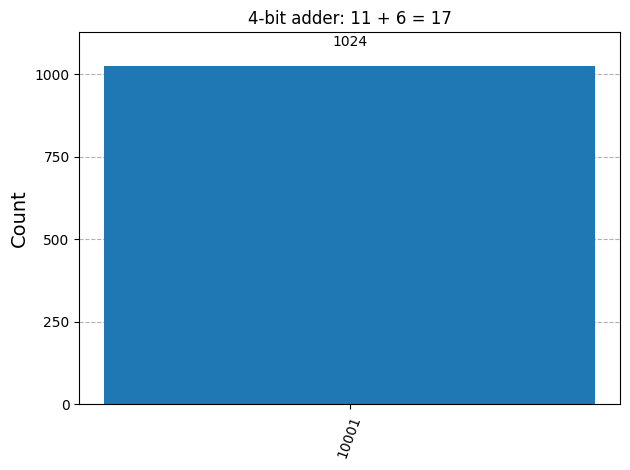

In [12]:
counts = run_counts([qc])[0]
expected_bits = f"{a + b:05b}"
assert counts == {expected_bits: 1024}, counts
measured = int(max(counts, key=counts.get), 2)
print(f"{a} + {b}: measured {counts} -> {measured} (expected {a + b})")
plot_histogram(counts, title=f"4-bit adder: {a} + {b} = {a + b}")

### Observations

- All 1,024 shots produced 10001 = 17 for 1011 + 0110 (11 + 6). The carry-out is 1 and the lower four sum bits are 0001.
- Design: The 4-bit solution extends the supplied SUM, CARRY, and reverse-CARRY blocks without changing their gate sequences. It uses 13 qubits, 14 Toffoli (CCX) gates, and 16 CNOT (CX) gates.
- Output interpretation: The inputs are unsigned 4-bit integers from 0 to 15. The five measured bits include the final carry-out; for example, 1011 + 0110 = 10001 (11 + 6 = 17).
- Data provenance: The counts and histogram images were regenerated by executing the displayed Qiskit circuits with the local ideal Aer SamplerV2, seed 4, and no noise model. Expected sums are computed separately for comparison.
- Histogram reading: The vertical axes show shot counts. Each selected test has one bar with 1,024 counts at the expected bitstring, corresponding to relative frequency 1.
- Scope: These results verify unsigned 4-bit addition for basis-state inputs under ideal simulation. Hardware performance and behavior under noise were not evaluated.


### Test cases

Six cases, chosen to cover the edge cases:

| case | why |
|---|---|
| 0 + 0 | all-zero input |
| 5 + 2 | no carries generated |
| 7 + 1 | carry ripples through bits 0→3 without overflow |
| 9 + 7 | overflow into the carry-out bit |
| 15 + 15 | maximum operands, every carry set |
| 15 + 0 with $c_{in}=1$ | uses the carry-in qubit $c_0$: one carry propagates through all 4 bits |

On the ideal simulator, the output is deterministic, so each histogram should show one bar with 1,024 counts at the binary value of the expected sum (relative frequency 1).

In [13]:
test_cases = [  # (a, b, cin)
    (0, 0, 0),
    (5, 2, 0),
    (7, 1, 0),
    (9, 7, 0),
    (15, 15, 0),
    (15, 0, 1),
]

circuits = [ripple_carry_adder(4, a, b, cin) for a, b, cin in test_cases]
all_counts = run_counts(circuits)

print(f"{'a':>3} {'b':>3} {'cin':>4} | {'expected':>11} | {'measured':>11} | result")
print("-" * 60)
for (a, b, cin), counts in zip(test_cases, all_counts):
    expected = a + b + cin
    measured = int(max(counts, key=counts.get), 2)
    ok = counts == {f"{expected:05b}": 1024}
    assert ok, f"Unexpected simulator counts: {counts}"
    print(
        f"{a:>3} {b:>3} {cin:>4} | {expected:>3} ({expected:05b}) | "
        f"{measured:>3} ({measured:05b}) | {'PASS' if ok else 'FAIL'}"
    )

  a   b  cin |    expected |    measured | result


------------------------------------------------------------
  0   0    0 |   0 (00000) |   0 (00000) | PASS
  5   2    0 |   7 (00111) |   7 (00111) | PASS
  7   1    0 |   8 (01000) |   8 (01000) | PASS
  9   7    0 |  16 (10000) |  16 (10000) | PASS
 15  15    0 |  30 (11110) |  30 (11110) | PASS
 15   0    1 |  16 (10000) |  16 (10000) | PASS


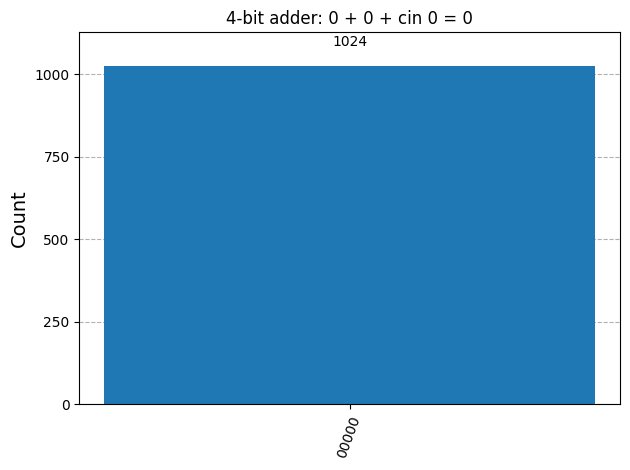

In [14]:
# Test 1: 0 + 0 = 0
a, b, cin = test_cases[0]
counts = all_counts[0]
title = f"4-bit adder: {a} + {b} + cin {cin} = {a + b + cin}"
plot_histogram(counts, title=title)

### Observations

- All 1,024 shots produced 00000 = 0 for 0000 + 0000 with carry-in 0.
- The sum and carry-out are zero, confirming correct behavior for all-zero inputs.
- Review corrections: Inherited installation logs were replaced with actual environment versions, stored outputs were regenerated, deprecated sampling calls were updated, histogram descriptions were corrected, and a PDF line break inside an f-string was fixed.


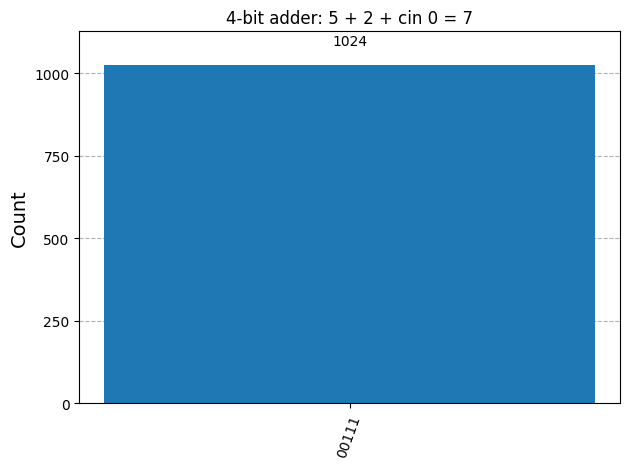

In [15]:
# Test 2: 5 + 2 = 7
a, b, cin = test_cases[1]
counts = all_counts[1]
title = f"4-bit adder: {a} + {b} + cin {cin} = {a + b + cin}"
plot_histogram(counts, title=title)

### Observations

- All 1,024 shots produced 00111 = 7 for 0101 + 0010 (5 + 2).
- The operands have no overlapping 1 bits, so no carry is generated and the carry-out is 0.


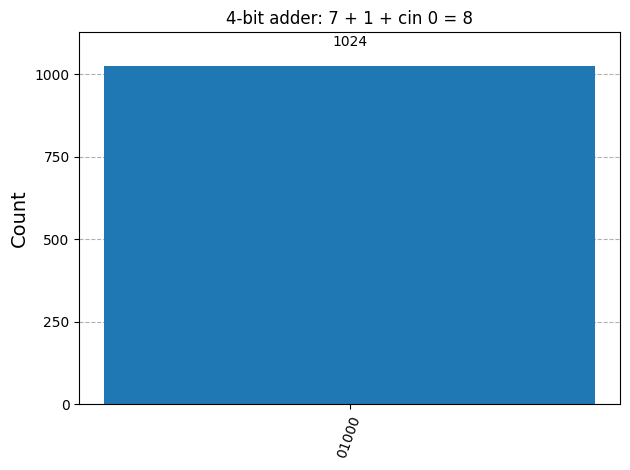

In [16]:
# Test 3: 7 + 1 = 8
a, b, cin = test_cases[2]
counts = all_counts[2]
title = f"4-bit adder: {a} + {b} + cin {cin} = {a + b + cin}"
plot_histogram(counts, title=title)

### Observations

- All 1,024 shots produced 01000 = 8 for 0111 + 0001 (7 + 1).
- The carry propagates through the lower three bit positions into bit 3; the final carry-out remains 0.


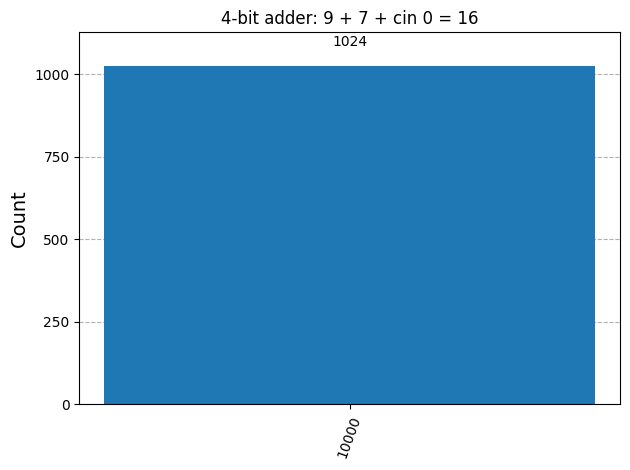

In [17]:
# Test 4: 9 + 7 = 16
a, b, cin = test_cases[3]
counts = all_counts[3]
title = f"4-bit adder: {a} + {b} + cin {cin} = {a + b + cin}"
plot_histogram(counts, title=title)

### Observations

- All 1,024 shots produced 10000 = 16 for 1001 + 0111 (9 + 7).
- The lower four sum bits are 0000 and the carry-out is 1, confirming overflow into the fifth output bit.


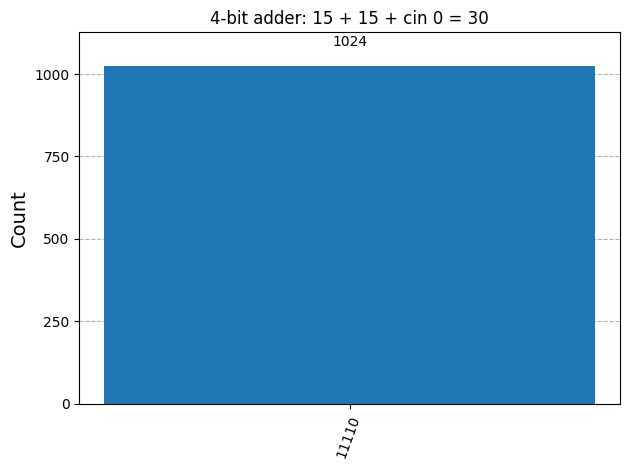

In [18]:
# Test 5: 15 + 15 = 30
a, b, cin = test_cases[4]
counts = all_counts[4]
title = f"4-bit adder: {a} + {b} + cin {cin} = {a + b + cin}"
plot_histogram(counts, title=title)

### Observations

- All 1,024 shots produced 11110 = 30 for 1111 + 1111 (15 + 15), with carry-in 0.
- Both operands have their maximum 4-bit value. The lower sum bits are 1110 and the carry-out is 1.


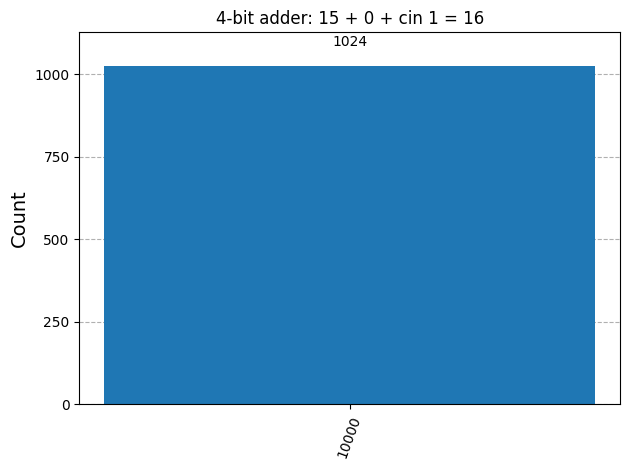

In [19]:
# Test 6: 15 + 0 + carry-in 1 = 16
a, b, cin = test_cases[5]
counts = all_counts[5]
title = f"4-bit adder: {a} + {b} + cin {cin} = {a + b + cin}"
plot_histogram(counts, title=title)

### Observations

- All 1,024 shots produced 10000 = 16 for 1111 + 0000 with carry-in 1 (15 + 0 + 1).
- The input carry propagates through all four bit positions, leaving lower sum bits 0000 and carry-out 1.
- Selected tests: All six histogram cases passed with 1,024 shots each. They cover zero inputs, no carry, carry propagation, overflow, maximum operands, and a nonzero carry-in.
- Exhaustive verification: All 512 operand/carry-in combinations passed with zero failures. The check also confirmed that the a register and initial carry-in are preserved and the three internal carry qubits return to zero.
- Assignment coverage: The single PDF includes the complete 4-bit solution code, executed test outputs, and histograms, satisfying the stated submission requirements.


### Exhaustive check

The histograms only show the measured output bits. This cell checks all $16 \times 16 \times 2 = 512$ inputs (every $a$, $b$, $c_{in}$) using the exact statevector of the unmeasured circuit and verifies that:

* the $b$ register and q12 hold $a + b + c_{in}$,
* the $a$ register and $c_0$ come back unchanged,
* the internal carry qubits $c_1, c_2, c_3$ return to $|0\rangle$, so no garbage is left behind.

In [20]:
# sum() above is the quantum SUM block, so use a separate register reader.
def read_register(state, qubits):
    """Read qubits as an integer; the first qubit is least significant."""
    return int("".join(state[q] for q in reversed(qubits)), 2)


n = 4
failures = 0
checked = 0
for cin in (0, 1):
    for a in range(2**n):
        for b in range(2**n):
            circuit = ripple_carry_adder(n, a, b, cin, measure=False)
            probs = Statevector(circuit).probabilities_dict()
            assert len(probs) == 1, "output should be a single basis state"
            assert abs(float(next(iter(probs.values()))) - 1.0) < 1e-12
            state = next(iter(probs))[::-1]  # state[k] is qubit k
            sum_qubits = [adder_qubits(i)[2] for i in range(n)] + [3 * n]
            a_qubits = [adder_qubits(i)[1] for i in range(n)]
            carry_qubits = [adder_qubits(i)[0] for i in range(1, n)]
            s = read_register(state, sum_qubits)
            a_out = read_register(state, a_qubits)
            carries_clean = read_register(state, carry_qubits) == 0
            if not (s == a + b + cin and a_out == a
                    and int(state[0]) == cin and carries_clean):
                failures += 1
                print(f"FAIL: a={a} b={b} cin={cin} -> state {state}")
            checked += 1

assert checked == 512
assert failures == 0, f"{failures} input combinations failed"
print(f"{checked} input combinations checked, {failures} failures")

512 input combinations checked, 0 failures
